In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from collections import defaultdict as dd
import seaborn as sns
from sklearn.datasets import load_iris

from sklearn.linear_model import LogisticRegression as LogReg
from sklearn.preprocessing import PolynomialFeatures as PF
from sklearn.metrics import confusion_matrix as CM
from sklearn.metrics import ConfusionMatrixDisplay as CMD
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier as MLPc
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_error as mae

from sklearn.datasets import fetch_california_housing
from sklearn.metrics import f1_score
from sklearn.metrics import recall_score as rs
from sklearn.metrics import accuracy_score as acc
from sklearn.tree import plot_tree as pt
from sklearn.datasets import make_classification as mc
from sklearn.datasets import make_regression as mr
from sklearn.datasets import make_blobs as mb
from sklearn.preprocessing import StandardScaler as SC
from sklearn.datasets import load_iris

###1. Загрузите встроенные данные sklearn.datasets.load_iris, взяв только последние два столбца (длина и ширина лепестков). Изобразите их на диаграмме рассеяния, подкрасив каждый класс некоторым цветом.

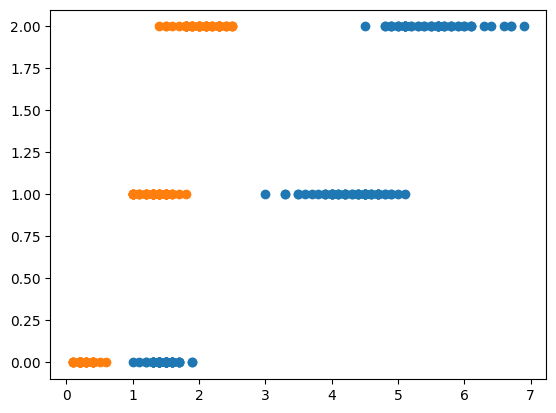

In [ ]:
x = load_iris(as_frame=True).frame[['petal length (cm)',	'petal width (cm)']]
y = load_iris(as_frame=True).frame[['target']]
plt.scatter(x.iloc[:,0],y)
plt.scatter(x.iloc[:,1],y)

###2. Обучите модель классификационного дерева принятия решений sklearn.tree.DecisionTreeClassifier глубины 4, используя энтропию. Визуализируйте соответствующий граф дерева принятия решений.

In [ ]:
x,y = mc(10000)
m = DTC(criterion = 'entropy',max_depth=4)
m.fit(x,y)
display(m.score(x,y))

fig,ax = plt.subplots(1,figsize=(25,15),dpi=1000)
pt(m,ax=ax,fontsize=10)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

###3. Обучите модель классификационного дерева принятия решений sklearn.tree.DecisionTreeClassifier с разными глубинами (1, 2, 3, 4, 10), используя энтропию, и визуализируйте в каждом случае полученные разделяющие области.

0.4

depth is 1


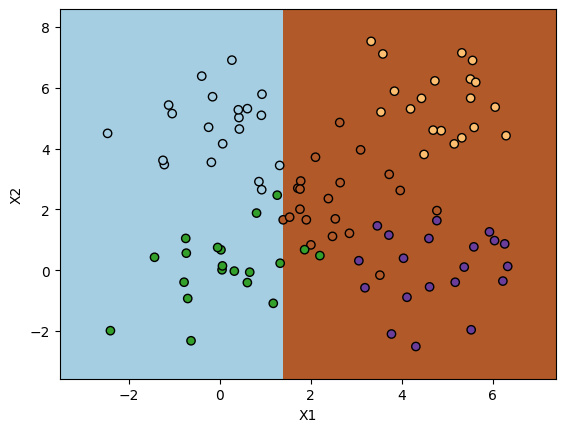

0.78

depth is 2


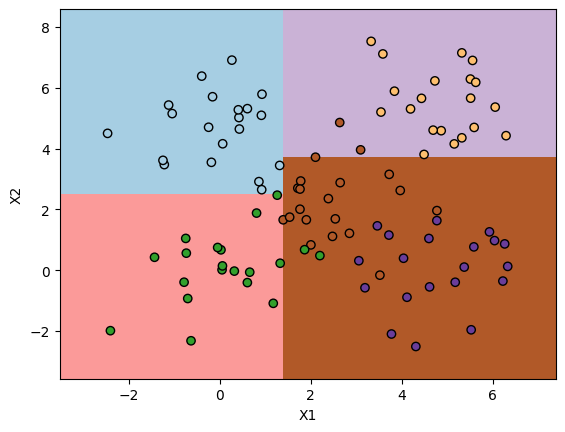

0.94

depth is 3


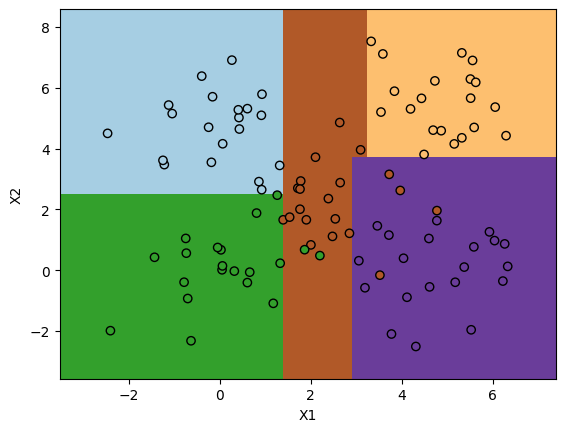

0.99

depth is 4


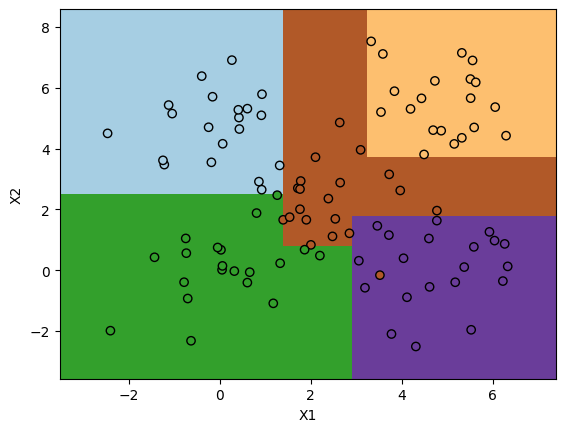

1.0

depth is 10


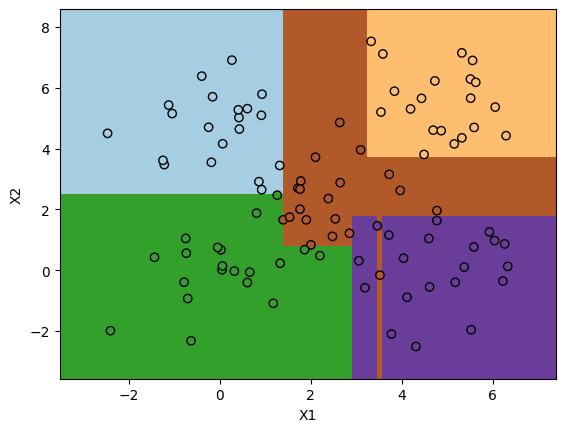

In [ ]:
def visualise(clf_tree,X,y):
    X0 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, X.shape[0])
    X1 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, X.shape[0])
    X0_grid, X1_grid = np.meshgrid(X0, X1)

    y_predict = clf_tree.predict(np.c_[X0_grid.ravel(), X1_grid.ravel()]).reshape(X0_grid.shape)

    plt.pcolormesh(X0_grid, X1_grid, y_predict, cmap=plt.cm.Paired, shading='auto')

    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors='black', linewidth=1)

    plt.xlabel('X1')
    plt.ylabel('X2')

    plt.show()

x,y = mb(100,n_features=2, centers = ((0,5),(0,0),(5,5),(5,0),(2.5,2.5)))
l=(1, 2, 3, 4, 10)
for i in l:
  m = DTC(criterion = 'entropy',max_depth=i)
  m.fit(x,y)
  display(m.score(x,y))
  print(f'depth is {i}')
  visualise(m,x,y)

###4.Выведите необходимые метрики для оценки работы моделей с разными глубинами. Сделайте вывод о том, какая модель лучше классифицирует данные.

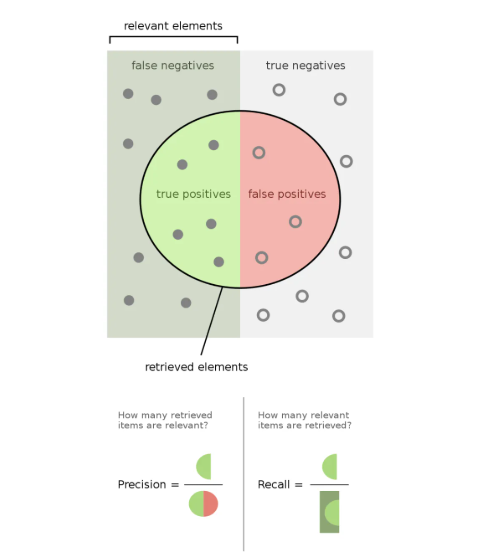

$\text{F1} = \frac{2 * \text{TP}}{2 * \text{TP} + \text{FP} + \text{FN}}$

depth is 1

Score is 0.4

F1 score is 0.4

Recall score is 0.4

Visual representation of the decision surfaces:


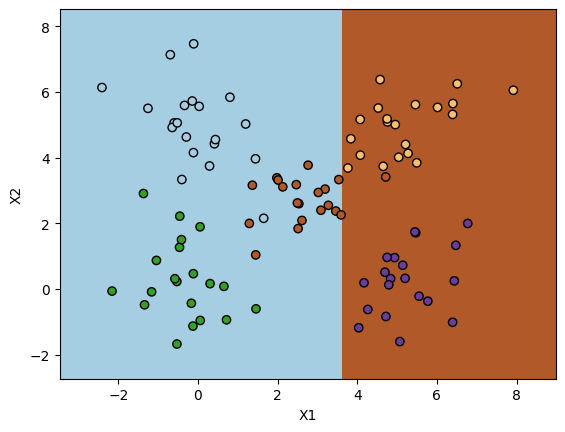


Confusion matrix:


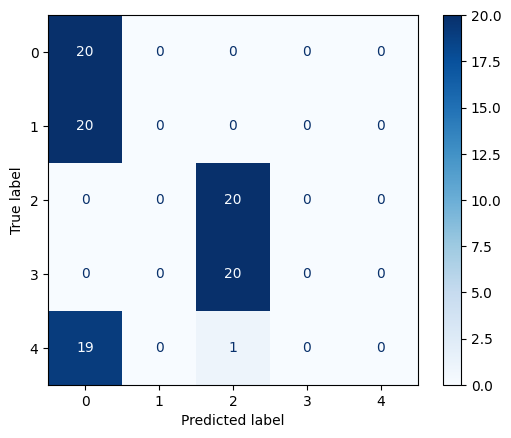






depth is 2

Score is 0.78

F1 score is 0.78

Recall score is 0.78

Visual representation of the decision surfaces:


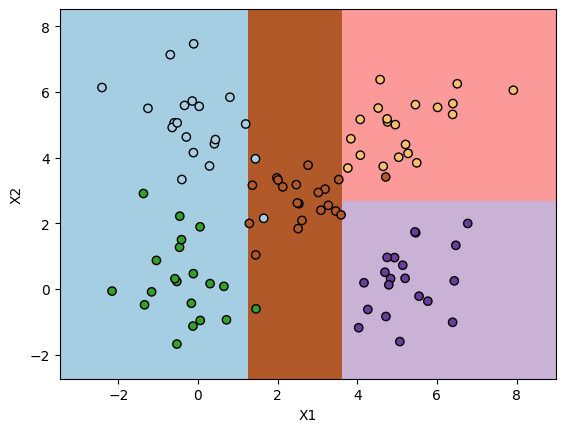


Confusion matrix:


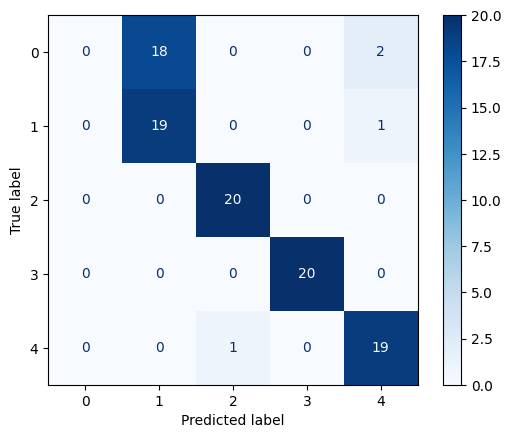






depth is 3

Score is 0.97

F1 score is 0.97

Recall score is 0.97

Visual representation of the decision surfaces:


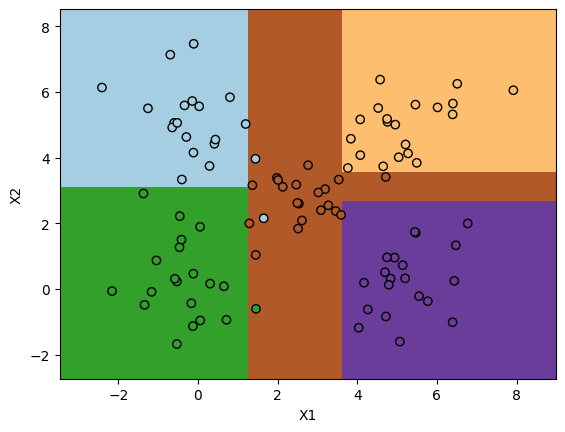


Confusion matrix:


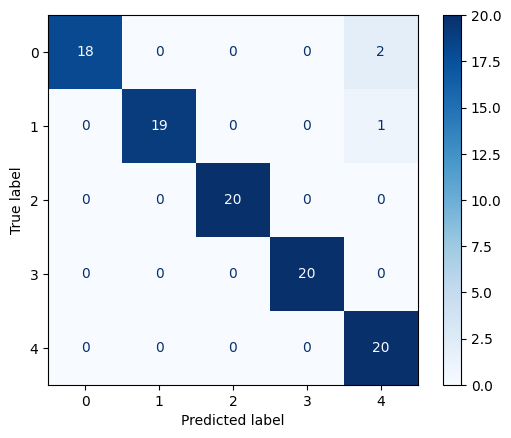






depth is 4

Score is 0.98

F1 score is 0.98

Recall score is 0.9800000000000001

Visual representation of the decision surfaces:


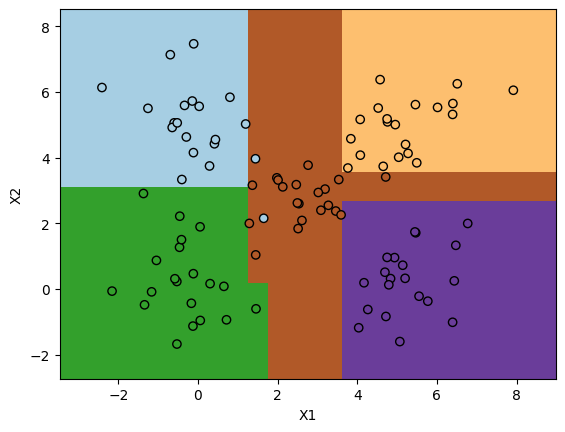


Confusion matrix:


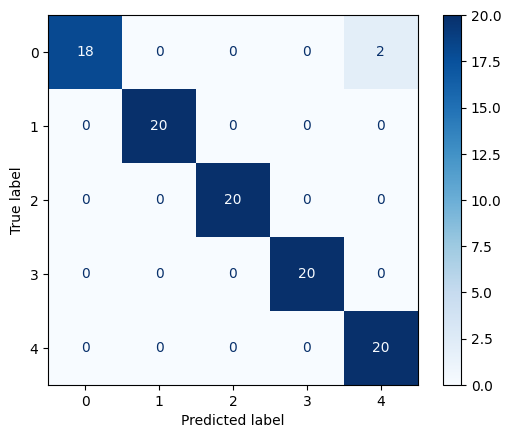






depth is 10

Score is 1.0

F1 score is 1.0

Recall score is 1.0

Visual representation of the decision surfaces:


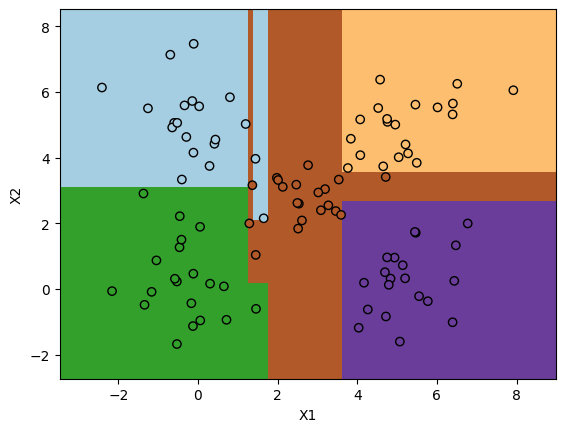


Confusion matrix:


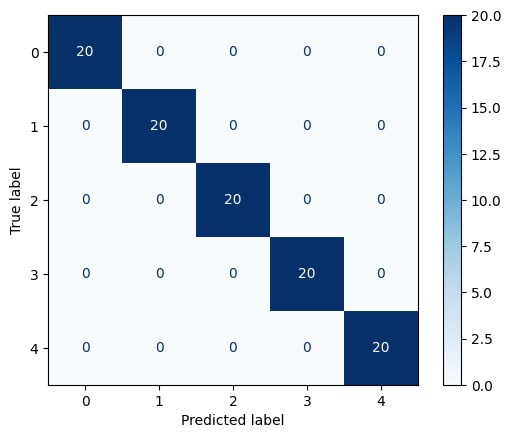

In [ ]:
def visualise(clf_tree,X,y):
    X0 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, X.shape[0])
    X1 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, X.shape[0])
    X0_grid, X1_grid = np.meshgrid(X0, X1)

    y_predict = clf_tree.predict(np.c_[X0_grid.ravel(), X1_grid.ravel()]).reshape(X0_grid.shape)

    plt.pcolormesh(X0_grid, X1_grid, y_predict, cmap=plt.cm.Paired, shading='auto')

    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors='black', linewidth=1)

    plt.xlabel('X1')
    plt.ylabel('X2')
    print(f'\nVisual representation of the decision surfaces:')
    plt.show()
    print(f'\nConfusion matrix:')
    CMD(CM(y,m.predict(X))).plot(cmap=plt.cm.Blues)
    plt.show()

x,y = mb(100,n_features=2, centers = ((0,5),(0,0),(5,5),(5,0),(2.5,2.5)))
l=(1, 2, 3, 4, 10)
for i in l:
  m = DTC(criterion = 'entropy',max_depth=i)
  m.fit(x,y)

  print(f'depth is {i}')
  print()
  print(f'Score is {m.score(x,y)}')
  print()
  print(f'F1 score is {f1_score(y,m.predict(x),average="micro")}')
  #print(f'Accuracy is {acc(y,m.predict(x))}')
  print()
  print(f'Recall score is {rs(y,m.predict(x),average="macro")}')
  visualise(m,x,y)
  print('\n\n\n\n')

###5. Загрузите весь датасет load_iris. Обучите модель классификационного дерева принятия решений sklearn.tree.DecisionTreeClassifier глубины 4, используя энтропию. Визуализируйте соответствующий граф дерева решений. Оцените качество работы модели.

In [ ]:
def visualise(clf_tree,X,y):
    #X0 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, X.shape[0])
    #X1 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, X.shape[0])
    #X0_grid, X1_grid = np.meshgrid(X0, X1)
#
    #y_predict = clf_tree.predict(np.c_[X0_grid.ravel(), X1_grid.ravel()]).reshape(X0_grid.shape)
#
    #plt.pcolormesh(X0_grid, X1_grid, y_predict, cmap=plt.cm.Paired, shading='auto')
#
    #scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors='black', linewidth=1)
#
    #plt.xlabel('X1')
    #plt.ylabel('X2')
    #print(f'\nVisual representation of the decision surfaces:')
    #plt.show()
    print(f'\nConfusion matrix:')
    CMD(CM(y,m.predict(X))).plot(cmap=plt.cm.Blues)
    plt.show()
    print(f'\nTree:')
    fig,ax = plt.subplots(1,figsize=(25,15),dpi=1000)
    pt(m,ax=ax,fontsize=10)
    plt.show()


In [ ]:
df = load_iris(as_frame=True).frame
y = df[['target']]
x = df.drop(['target'],axis=1)
m = DTC(criterion = 'entropy',max_depth=4)
m.fit(x,y)
print(f'Score is {m.score(x,y)}')
print()
print(f'F1 score is {f1_score(y,m.predict(x),average="micro")}')
#print(f'Accuracy is {acc(y,m.predict(x))}')
print()
print(f'Recall score is {rs(y,m.predict(x),average="macro")}')
visualise(m,x,y)

Output hidden; open in https://colab.research.google.com to view.

###6. Загрузите встроенные данные sklearn.datasets.california_housing, взяв только столбец AveBedrms в качестве единственного признака. Изобразите данные на диаграмме рассеяния так, чтобы на одной оси были отмечены значения признака, а на другой - целевой переменной.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


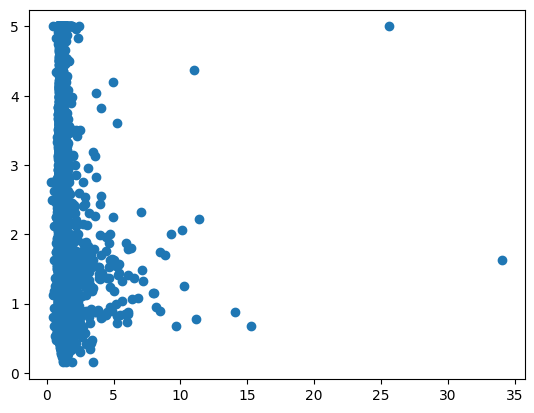


Score is 0.679172913720798


In [ ]:
df = fetch_california_housing(as_frame=True).frame
display(df.head())
x = df[['AveBedrms']]
y = df[[fetch_california_housing(as_frame=True).target.name]]
m = DTR(criterion = 'squared_error')
scaler = SC()
x1 = scaler.fit_transform(x)
y1 = scaler.fit_transform(y)
m.fit(x1,y1)
plt.scatter(x,y)
plt.show()
print()
print(f'Score is {m.score(x1,y1)}')

###7. Обучите модель регрессионного дерева принятия решений sklearn.tree.DecisionTreeRegressor, зафиксировав random_state=0, а остальными гиперпараметрами по умолчению.

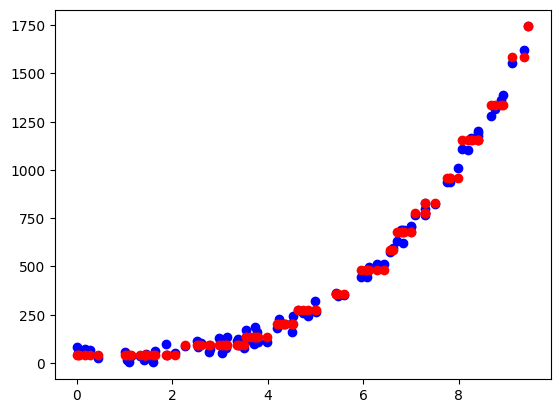


Score is 0.996425263111795


In [ ]:
x = np.random.rand(100, 1) * 10
y = 2 * (x ** 3) - 5 * x + np.random.rand(100,1) * 100
m=DTR(criterion='squared_error',max_depth=4)
m.fit(x,y)
plt.scatter(x,y,color='blue')
plt.scatter(x,m.predict(x),color='red')
plt.show()
print()
print(f'Score is {m.score(x,y)}')

###8. Визуализируйте соответствующий граф дерева решений и получившуюся кусочную линию регрессии.

In [ ]:
x = np.random.rand(100, 1) * 10
y = 2 * (x ** 3) - 5 * x + np.random.rand(100,1) * 100
m=DTR(criterion='squared_error',max_depth=4)
m.fit(x,y)
plt.scatter(x,y,color='blue')
plt.scatter(x,m.predict(x),color='red')
plt.show()
print()
print(f'Score is {m.score(x,y)}')
fig,ax = plt.subplots(1,figsize=(25,15),dpi=1000)
pt(m,ax=ax,fontsize=10)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

###9. Оцените качество работы модели. Создайте новое наблюдение и сделайте предсказание на нём

Example point (lime green star):
x = 5
y = 312.8624405534472


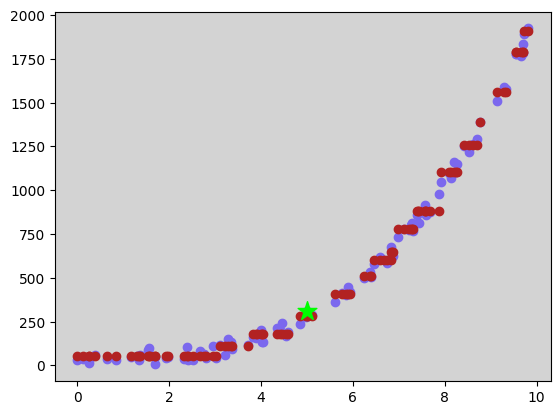


Score is 0.9971480036470851

MAE is 22.925200515680967
MSE is 859.2800848206675


In [ ]:
x = np.random.rand(100, 1) * 10
def f(x):
  return 2 * (x ** 3) - 5 * x + np.random.rand(x.shape[0],1) * 100
y = f(x)
m=DTR(criterion='squared_error',max_depth=4)
m.fit(x,y)

fig, ax = plt.subplots(1)
ax.set_facecolor('lightgray')
plt.scatter(x,y,color='mediumslateblue')
plt.scatter(x,m.predict(x),color='firebrick')

x1 = np.array([5])
y1 = f(x1)
print(f'Example point (lime green star):\nx = {x1[0]}\ny = {y1[0][0]}')
plt.scatter(x1,y1,color='lime',marker='*',s=200)


plt.show()
print()
print(f'Score is {m.score(x,y)}')
print()
print(f'MAE is {mae(y,m.predict(x))}')
print(f'MSE is {mse(y,m.predict(x))}')

###10. Загрузите весь датасет fetch_california_housing. Обучите ту же модель. Визуализируйте соответствующий граф дерева решений и оцените качество работы модели.

In [ ]:
df = fetch_california_housing(as_frame=True).frame
display(df.head())
x = df.drop([fetch_california_housing(as_frame=True).target.name],axis=1)
y = df[[fetch_california_housing(as_frame=True).target.name]]
m = DTR(criterion = 'squared_error')
scaler = SC()
x1 = scaler.fit_transform(x)
y1 = scaler.fit_transform(y)
m.fit(x1,y1)


print()
print(f'Score is {m.score(x1,y1)}')
print()
print(f'MAE is {mae(y1,m.predict(x1))}')
print(f'MSE is {mse(y1,m.predict(x1))}')

fig,ax = plt.subplots(1,figsize=(25,15),dpi=1000)
pt(m,ax=ax,fontsize=10)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [7]:
df = fetch_california_housing(as_frame=True).frame
display(df.head())
x = df.drop([fetch_california_housing(as_frame=True).target.name],axis=1)
y = df[[fetch_california_housing(as_frame=True).target.name]]
m = DTR(criterion = 'squared_error',max_depth=9)
scaler = SC()
x1 = scaler.fit_transform(x)
y1 = scaler.fit_transform(y)
m.fit(x1,y1)


print()
print(f'Score is {m.score(x1,y1)}')
print()
print(f'MAE is {mae(y1,m.predict(x1))}')
print(f'MSE is {mse(y1,m.predict(x1))}')

fig,ax = plt.subplots(1,figsize=(25,15),dpi=1000)
pt(m,ax=ax,fontsize=10)
plt.show()